In [2]:
import pandas as pd
import json
import collections
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import requests
from tqdm import tqdm

In [3]:
METADATA_DIR = "../../../data/immunotherapy_cohorts/IMVigor210/EGAD00001003977-metadata"

# run_sample.csv has semicolon-separated key=value attributes
run_sample = pd.read_csv(f"{METADATA_DIR}/run_sample.csv")

def parse_sample_attributes(attr_str):
    attrs = {}
    if pd.isna(attr_str):
        return attrs
    for item in str(attr_str).split(";"):
        if "=" in item:
            k, v = item.split("=", 1)
            attrs[k.strip()] = v.strip()
    return attrs

attrs_df = run_sample["sample_attributes"].apply(parse_sample_attributes)
attrs_df = pd.DataFrame(list(attrs_df))

# Combine with run/sample accession IDs
meta = pd.concat([run_sample[["sample_alias", "sample_accession_id", "run_accession_id"]], attrs_df], axis=1)

# All 348 samples are RNA-seq (single library strategy: RNA-Seq, TruSeq RNA Exome)
rna_meta = meta.copy()

# Cast numeric fields
for col in ["os", "censOS", "FMOne mutation burden per MB", "Neoantigen burden per MB", "sizeFactor"]:
    rna_meta[col] = pd.to_numeric(rna_meta[col], errors="coerce")

# Canonical response label: responder = CR or PR
rna_meta["response_binary"] = rna_meta["Best Confirmed Overall Response"].map(
    {"CR": 1, "PR": 1, "SD": 0, "PD": 0}  # NE -> NaN automatically
)

print(f"Total samples in metadata:         {len(meta)}")
print(f"RNA-seq samples:                   {len(rna_meta)}")
print(f"  with OS + censOS:                {rna_meta['os'].notna().sum()}")
print(f"  with Best Confirmed Response:    {rna_meta['Best Confirmed Overall Response'].notna().sum()}")
print(f"  with binary label (excl. NE):    {rna_meta['response_binary'].notna().sum()}")
print()
print("Response breakdown:")
print(rna_meta["Best Confirmed Overall Response"].value_counts(dropna=False).to_string())
print()
print("binaryResponse breakdown:")
print(rna_meta["binaryResponse"].value_counts(dropna=False).to_string())

rna_meta.head(3)

Total samples in metadata:         348
RNA-seq samples:                   348
  with OS + censOS:                348
  with Best Confirmed Response:    348
  with binary label (excl. NE):    298

Response breakdown:
Best Confirmed Overall Response
PD    167
SD     63
NE     50
PR     43
CR     25

binaryResponse breakdown:
binaryResponse
SD/PD    230
CR/PR     68
NaN       50


,sample_alias,sample_accession_id,run_accession_id,Baseline ECOG Score,Best Confirmed Overall Response,censOS,ENA-CHECKLIST,Enrollment IC,IC Level,Immune phenotype,...,Sample collected pre-platinum,sizeFactor,TCGA Subtype,TC Level,Tissue,Tobacco Use History,binaryResponse,FMOne mutation burden per MB,Neoantigen burden per MB,response_binary
0,SAM00b9e5c52da9,EGAN00001627928,EGAR00001652884,1,NE,1,ERC000026,IC1,IC1,excluded,...,Y,1.217072,III,TC0,bladder,PREVIOUS,NaN,NaN,NaN,NaN
1,SAM0257bbbbd388,EGAN00001627900,EGAR00001652885,1,SD,1,ERC000026,IC1,IC1,excluded,...,Y,1.567678,II,TC0,bladder,PREVIOUS,SD/PD,18.0,4.686275,0.0
2,SAM025b45c27e05,EGAN00001627771,EGAR00001652886,0,PD,1,ERC000026,IC1,IC1,desert,...,N,1.648825,III,TC0,bladder,PREVIOUS,SD/PD,1.0,0.313725,0.0


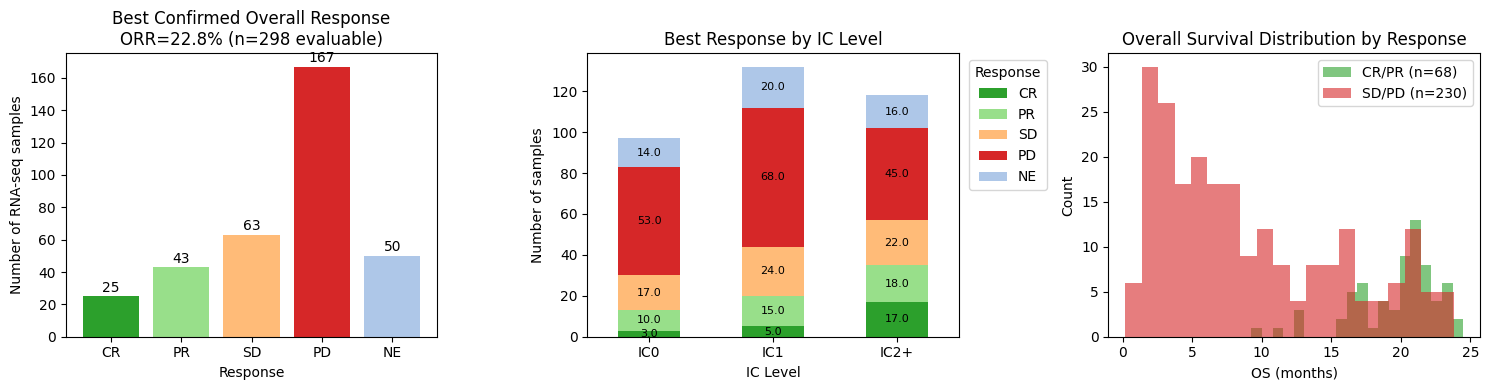

            n  CR  PR  SD  PD  NE  missing_response  has_OS  median_OS  os_event_rate    ORR (%)
IC Level                                                                                        
IC0        97   3  10  17  53  14                 0      97   5.880903       0.257732  15.662651
IC1       132   5  15  24  68  20                 0     132   7.917864       0.295455  17.857143
IC2+      118  17  18  22  45  16                 0     118  11.663244       0.432203  34.313725


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# --- Best Response distribution ---
ax = axes[0]
response_order = ["CR", "PR", "SD", "PD", "NE"]
colors = {"CR": "#2ca02c", "PR": "#98df8a", "SD": "#ffbb78", "PD": "#d62728", "NE": "#aec7e8"}
resp_counts = rna_meta["Best Confirmed Overall Response"].value_counts().reindex(response_order, fill_value=0)
bars = ax.bar(resp_counts.index, resp_counts.values,
              color=[colors[r] for r in resp_counts.index])
ax.set_title("Best Confirmed Overall Response (IMVigor210)")
ax.set_xlabel("Response")
ax.set_ylabel("Number of RNA-seq samples")
for bar, val in zip(bars, resp_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
            str(val), ha="center", va="bottom", fontsize=10)
total_evaluable = rna_meta["response_binary"].notna().sum()
orr = rna_meta["response_binary"].sum() / total_evaluable * 100
ax.set_title(f"Best Confirmed Overall Response\nORR={orr:.1f}% (n={total_evaluable} evaluable)")

# --- IC Level breakdown ---
ax = axes[1]
ic_order = ["IC0", "IC1", "IC2+"]
ic_colors = {"IC0": "#aec7e8", "IC1": "#1f77b4", "IC2+": "#003f8a"}
ic_resp = (
    rna_meta[rna_meta["Best Confirmed Overall Response"].notna()]
    .groupby(["IC Level", "Best Confirmed Overall Response"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=ic_order, columns=response_order, fill_value=0)
)
ic_resp.plot(kind="bar", stacked=True, ax=ax,
             color=[colors[c] for c in ic_resp.columns], legend=True, rot=0)
ax.set_title("Best Response by IC Level")
ax.set_xlabel("IC Level")
ax.set_ylabel("Number of samples")
ax.legend(title="Response", bbox_to_anchor=(1.01, 1), loc="upper left")
for c in ax.containers:
    ax.bar_label(c, label_type="center", fmt="%d", fontsize=8,
                 labels=[v if v > 0 else "" for v in c.datavalues])

# --- OS distribution by response ---
ax = axes[2]
resp_color_map = {"CR/PR": "#2ca02c", "SD/PD": "#d62728"}
for label, color in resp_color_map.items():
    subset = rna_meta[(rna_meta["binaryResponse"] == label) & rna_meta["os"].notna()]["os"]
    ax.hist(subset, bins=20, alpha=0.6, label=f"{label} (n={len(subset)})", color=color)
ax.set_title("Overall Survival Distribution by Response")
ax.set_xlabel("OS (months)")
ax.set_ylabel("Count")
ax.legend()

plt.tight_layout()
plt.savefig("IMVigor210_cohort_summary.png", dpi=150, bbox_inches="tight")
plt.show()

# Tabular summary by IC Level
summary = rna_meta.groupby("IC Level").agg(
    n=("sample_accession_id", "count"),
    CR=("Best Confirmed Overall Response", lambda x: (x == "CR").sum()),
    PR=("Best Confirmed Overall Response", lambda x: (x == "PR").sum()),
    SD=("Best Confirmed Overall Response", lambda x: (x == "SD").sum()),
    PD=("Best Confirmed Overall Response", lambda x: (x == "PD").sum()),
    NE=("Best Confirmed Overall Response", lambda x: (x == "NE").sum()),
    missing_response=("Best Confirmed Overall Response", lambda x: x.isna().sum()),
    has_OS=("os", lambda x: x.notna().sum()),
    median_OS=("os", "median"),
    os_event_rate=("censOS", lambda x: (x == 0).sum() / x.notna().sum()),
).reindex(ic_order)
summary["ORR (%)"] = (summary["CR"] + summary["PR"]) / (summary["n"] - summary["NE"] - summary["missing_response"]) * 100
print(summary.to_string())

In [5]:
# Join RNA-seq sample accession IDs with file accession IDs (EGAFs)
sample_file = pd.read_csv(f"{METADATA_DIR}/sample_file.csv")

rna_accessions = set(rna_meta["sample_accession_id"])
rna_files = sample_file[sample_file["sample_accession_id"].isin(rna_accessions)].copy()

print(f"RNA-seq samples:  {len(rna_accessions)}")
print(f"Fastq files (2 per sample, paired-end): {len(rna_files)}")
print(f"Unique EGAF IDs:  {rna_files['file_accession_id'].nunique()}")
print()

# Save EGAF IDs for download
# Command:
# cat /data/rbg/users/ashyamal/RNA-FM-benchmarking/data/immunotherapy_cohorts/IMVigor210/RNA/rna_seq_egaf_ids.txt | \
#   xargs -P 8 -I {} pyega3 -cf /data/rbg/users/ashyamal/credentials.json -c 2 fetch \
#     --output-dir /data/rbg/users/ashyamal/RNA-FM-benchmarking/data/immunotherapy_cohorts/IMVigor210/RNA \
#     {}
OUT_DIR = "../../../data/immunotherapy_cohorts/IMVigor210/RNA"
egaf_path = f"{OUT_DIR}/rna_seq_egaf_ids.txt"
rna_files["file_accession_id"].to_csv(egaf_path, index=False, header=False)
print(f"Saved {len(rna_files)} EGAF IDs to {egaf_path}")

# Save a full manifest with sample alias, clinical info for easy cross-referencing
# Note: sample_alias already comes from rna_files; exclude it from rna_meta to avoid duplicate columns
manifest = rna_files.merge(
    rna_meta[[
        "sample_accession_id",
        "Best Confirmed Overall Response", "response_binary",
        "binaryResponse", "os", "censOS",
        "IC Level", "TC Level", "Immune phenotype",
        "Lund2", "TCGA Subtype",
        "FMOne mutation burden per MB", "Neoantigen burden per MB",
        "Baseline ECOG Score", "Received platinum", "Met Disease Status", "Tissue"
    ]],
    on="sample_accession_id", how="left"
).sort_values(["sample_alias", "file_name"])

manifest_path = f"{OUT_DIR}/rna_seq_download_manifest.csv"
manifest.to_csv(manifest_path, index=False)
print(f"Saved download manifest to {manifest_path}")
manifest.head(6)

RNA-seq samples:  348
Fastq files (2 per sample, paired-end): 696
Unique EGAF IDs:  696

Saved 696 EGAF IDs to ../../../data/immunotherapy_cohorts/IMVigor210/RNA/rna_seq_egaf_ids.txt
Saved download manifest to ../../../data/immunotherapy_cohorts/IMVigor210/RNA/rna_seq_download_manifest.csv


,sample_accession_id,sample_alias,file_name,file_accession_id,Best Confirmed Overall Response,response_binary,binaryResponse,os,censOS,IC Level,TC Level,Immune phenotype,Lund2,TCGA Subtype,FMOne mutation burden per MB,Neoantigen burden per MB,Baseline ECOG Score,Received platinum,Met Disease Status,Tissue
526,EGAN00001627928,SAM00b9e5c52da9,GO29293_RNAseq_GO29293_ngs_rna_targrna_rnaacce...,EGAF00001873123,NE,NaN,NaN,1.905544,1,IC1,TC0,excluded,UroB,III,NaN,NaN,1,Y,Visceral,bladder
527,EGAN00001627928,SAM00b9e5c52da9,GO29293_RNAseq_GO29293_ngs_rna_targrna_rnaacce...,EGAF00001873124,NE,NaN,NaN,1.905544,1,IC1,TC0,excluded,UroB,III,NaN,NaN,1,Y,Visceral,bladder
470,EGAN00001627900,SAM0257bbbbd388,GO29293_RNAseq_GO29293_ngs_rna_targrna_rnaacce...,EGAF00001873125,SD,0.0,SD/PD,15.638604,1,IC1,TC0,excluded,Genomically unstable,II,18.0,4.686275,1,Y,Visceral,bladder
471,EGAN00001627900,SAM0257bbbbd388,GO29293_RNAseq_GO29293_ngs_rna_targrna_rnaacce...,EGAF00001873126,SD,0.0,SD/PD,15.638604,1,IC1,TC0,excluded,Genomically unstable,II,18.0,4.686275,1,Y,Visceral,bladder
212,EGAN00001627771,SAM025b45c27e05,GO29293_RNAseq_GO29293_ngs_rna_targrna_rnaacce...,EGAF00001873127,PD,0.0,SD/PD,8.772074,1,IC1,TC0,desert,Infiltrated,III,1.0,0.313725,0,Y,Liver,bladder
213,EGAN00001627771,SAM025b45c27e05,GO29293_RNAseq_GO29293_ngs_rna_targrna_rnaacce...,EGAF00001873128,PD,0.0,SD/PD,8.772074,1,IC1,TC0,desert,Infiltrated,III,1.0,0.313725,0,Y,Liver,bladder


In [6]:
import subprocess

egaf_path = f"{OUT_DIR}/rna_seq_egaf_ids.txt"
dataset_files_path = f"{METADATA_DIR}/dataset_files.txt"

result = subprocess.run(
    f"grep -Ff {egaf_path} {dataset_files_path} | awk '{{sum += $6}} END {{printf \"%.2f\", sum / 1e9}}'",
    shell=True, capture_output=True, text=True
)
print(f"Total RNA-seq download size: {result.stdout} GB")

Total RNA-seq download size: 1961.23 GB


In [7]:
# Number of samples with both RNA-seq and responder information that's note NE
labeled = rna_meta[rna_meta["response_binary"].notna()]
print(f"Samples with RNA-seq + responder/non-responder label (excl. NE): {len(labeled)}")
print(f"  Responders   (CR/PR): {(labeled['response_binary'] == 1).sum()}")
print(f"  Non-responders (SD/PD): {(labeled['response_binary'] == 0).sum()}")

Samples with RNA-seq + responder/non-responder label (excl. NE): 298
  Responders   (CR/PR): 68
  Non-responders (SD/PD): 230
